# Bankruptcy prediction with machine learning and LLMs
**What this project does.** It reproduces the method of *Advanced Default Risk Prediction in Small and Medium-Sized Enterprises Using Large Language Models* (Huang et al., Applied Sciences 2025) for the question **"will this company go bankrupt within a year?"**.
The paper's own data is proprietary, so the method is run on **three public datasets of financial ratios**:

| Dataset | Rows | Bankrupt | How it is evaluated | Role |
|---|---|---|---|---|
| American listed firms, 1999-2018 | 78,682 firm-years (8,971 firms) | 609 firms | train up to 2014, test 2015-2018 | **main, honest result** |
| Taiwan Economic Journal, 1999-2009 | 6,819 firms | 220 | stratified 5-fold CV (one row per firm) | independent confirmation |
| Polish manufacturing firms (UCI) | 43,405 firm-years in 5 files | 2,091 | random 80/20 split | benchmark; likely leakage (no firm IDs) |

**How the Polish files are defined** (UCI documentation): file `Nyear` holds the ratios from year N of the forecasting period and the label "bankrupt after 6-N years". So `1year` = bankruptcy **5 years ahead** (the hardest case; "horizon 1" in the code and file names) and `5year` = bankruptcy **1 year ahead** ("horizon 5"). Early notes in this project assumed the opposite; the tables below are labelled with the correct direction.

All numbers below are read from the saved files in `results/`, so this notebook only displays results; the code that produced them is in `src/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"
pd.set_option("display.width", 160)

## 1. Workflow
| Phase | What | Code |
|---|---|---|
| 1-2 | Load data, drop duplicates / mostly-missing columns, split, impute, three standardisations (Log, MinMax, Z-score) | `load_data.py`, `preprocess.py`, `american_prepare.py` |
| 3 | Regression analysis: pick six key ratios (L1-logistic path), OLS and logit tables, size sub-groups, robustness | `regression_analysis.py`, `american_regression.py` |
| 4 | Seven models x three standardisations, grid search, threshold from out-of-fold training scores | `run_models.py`, `american_models.py`, `taiwan_models.py` |
| 5 | LLM prompt learning (Qwen2.5-7B via Ollama): rate risk 1-10, three votes | `llm_prompt.py`, `american_llm.py` |
| 6 | LLM fine-tuning (LoRA on Qwen2.5-0.5B) | `llm_finetune.py`, `american_finetune.py`, `colab/` |
| extra | Altman Z baseline, confidence intervals, American-Taiwan transfer, SHAP, balanced neural net | `combined_results.py`, `confidence_intervals.py`, `cross_dataset.py`, `explain_shap.py`, `nn_balanced.py` |

**An important label fix (American data).** The raw `status_label` says "failed" in *every* year of a company that eventually failed. Used as-is, a model would only learn "is this a company that eventually fails". Here a firm-year is positive only in the **last year of a failed company** (the statement filed just before failure).

In [2]:
am = pd.read_csv(ROOT / "data/american/american_ratios.csv")
print("firm-years:", len(am), "| companies:", am.company.nunique(), "| positives (last year of a failed company):", int(am.bankrupt.sum()))
print("train <=2014 :", int((am.year <= 2014).sum()), "rows,", int(am[am.year <= 2014].bankrupt.sum()), "positives")
print("test 2015-18 :", int((am.year > 2014).sum()), "rows,", int(am[am.year > 2014].bankrupt.sum()), "positives")

firm-years: 78682 | companies: 8971 | positives (last year of a failed company): 609
train <=2014 : 66400 rows, 490 positives
test 2015-18 : 12282 rows, 119 positives


## 2. Regression analysis: the six key ratios (paper Section 4.1)

In [3]:
for name, f in (("American", RES/"american/key_features.json"), ("Polish (5 yrs ahead, file 1year)", RES/"key_features.json")):
    k = json.load(open(f))
    print(name)
    for r in k["key_features"]:
        print(f"   {r:34s} {k['definitions'][r]}")

American
   roa                                net income / total assets
   quick_ratio                        (current assets - inventory) / current liabilities
   debt_to_equity                     total liabilities / (total assets - total liabilities)
   market_value_to_liabilities        market value of equity / total liabilities
   net_margin                         net income / net sales
   assets_growth                      year-on-year growth of total assets
Polish (5 yrs ahead, file 1year)
   working_capital_to_assets          working capital / total assets
   liabilities_to_assets              total liabilities / total assets
   gross_profit_to_st_liabilities     gross profit / short-term liabilities
   gross_profit_3y_to_assets          gross profit (in 3 years) / total assets
   liquidity_to_operating_cost        (current assets - inventory - short-term liabilities) / (sales - gross profit - depreciation)
   cash_defensive_days                [(cash + short-term securities 

In [4]:
t = pd.read_csv(RES/"american/regression_baseline_logit.csv", index_col=0)
print("American baseline logit on the six key ratios (HC1 robust errors)")
t.round(4)

American baseline logit on the six key ratios (HC1 robust errors)


,coef,t,p,sig
const,-6.0490,-45.9046,0.0000,***
roa,0.0999,3.2665,0.0011,***
quick_ratio,-0.5313,-5.3637,0.0000,***
debt_to_equity,-0.1349,-3.8474,0.0001,***
market_value_to_liabilities,-1.5115,-9.7447,0.0000,***
net_margin,-0.2843,-6.6607,0.0000,***
assets_growth,-0.4065,-4.1973,0.0000,***


Market value relative to debt is the strongest signal (t about -9.7). Five of the six ratios keep their sign across both time windows and the 3-year target; only return on assets is unstable (it overlaps with net margin) - see `results/american/regression_robustness.csv`.

## 3. Seven models on each dataset

In [5]:
am_cmp = pd.read_csv(RES/"american/model_comparison_bankrupt.csv")
cols = ["accuracy", "f1_w", "precision_bankrupt", "recall_bankrupt", "f1_bankrupt", "auc"]
print("American, train <=2014 / test 2015-2018: mean over the three scalings (paper Table 8 style)")
am_cmp.groupby("model")[cols].mean().round(3).sort_values("auc", ascending=False)

American, train <=2014 / test 2015-2018: mean over the three scalings (paper Table 8 style)


,accuracy,f1_w,precision_bankrupt,recall_bankrupt,f1_bankrupt,auc
model,,,,,,
RF,0.982,0.983,0.186,0.246,0.211,0.912
XGBoost,0.981,0.983,0.195,0.289,0.230,0.910
LightGBM,0.974,0.980,0.164,0.395,0.229,0.907
DT,0.975,0.979,0.101,0.347,0.156,0.898
Logistic,0.928,0.954,0.040,0.266,0.070,0.780
SVM,0.967,0.975,0.063,0.218,0.093,0.776
NN,0.963,0.972,0.048,0.176,0.074,0.688


In [6]:
print("Every model x scaling, American (paper Table 7 style)")
am_cmp.sort_values(["model", "scaling"])[["model", "scaling"] + cols].round(3).reset_index(drop=True)

Every model x scaling, American (paper Table 7 style)


,model,scaling,accuracy,f1_w,precision_bankrupt,recall_bankrupt,f1_bankrupt,auc
0,DT,log,0.967,0.976,0.151,0.521,0.234,0.900
1,DT,minmax,0.990,0.985,0.000,0.000,0.000,0.894
2,DT,zscore,0.967,0.976,0.151,0.521,0.234,0.900
3,LightGBM,log,0.975,0.980,0.170,0.395,0.237,0.907
4,LightGBM,minmax,0.978,0.982,0.172,0.328,0.225,0.904
5,LightGBM,zscore,0.969,0.977,0.149,0.462,0.225,0.909
6,Logistic,log,0.940,0.961,0.074,0.445,0.127,0.875
7,Logistic,minmax,0.926,0.952,0.015,0.101,0.026,0.725
8,Logistic,zscore,0.919,0.949,0.032,0.252,0.057,0.740
9,NN,log,0.955,0.969,0.084,0.370,0.137,0.862


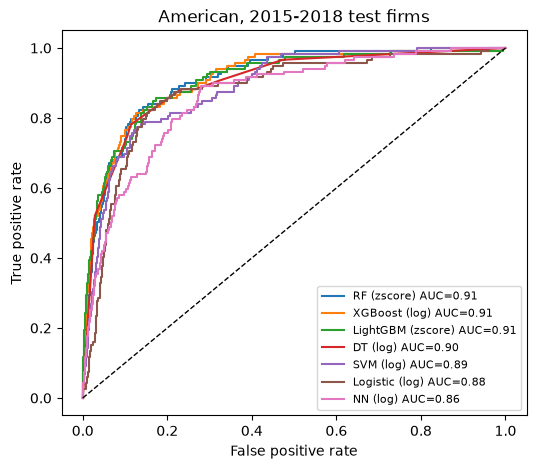

In [7]:
rocs = np.load(RES/"american/roc_bankrupt.npy", allow_pickle=True).item()
best = am_cmp.loc[am_cmp.groupby("model").auc.idxmax()].set_index("model")
fig, ax = plt.subplots(figsize=(6, 5))
for m, row in best.sort_values("auc", ascending=False).iterrows():
    fpr, tpr, auc = rocs[f"{m}|{row.scaling}"]
    ax.plot(fpr, tpr, label=f"{m} ({row.scaling}) AUC={auc:.2f}")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("American, 2015-2018 test firms"); ax.legend(fontsize=8); plt.show()

In [8]:
print("Taiwan, stratified 5-fold CV: mean over the three scalings")
pd.read_csv(RES/"taiwan/model_comparison.csv").groupby("model")[cols].mean().round(3).sort_values("auc", ascending=False)

Taiwan, stratified 5-fold CV: mean over the three scalings


,accuracy,f1_w,precision_bankrupt,recall_bankrupt,f1_bankrupt,auc
model,,,,,,
LightGBM,0.963,0.965,0.447,0.545,0.491,0.941
RF,0.957,0.961,0.385,0.553,0.454,0.941
XGBoost,0.958,0.961,0.393,0.562,0.462,0.935
Logistic,0.955,0.958,0.350,0.470,0.401,0.921
DT,0.940,0.949,0.277,0.536,0.366,0.893
SVM,0.945,0.950,0.267,0.403,0.321,0.867
NN,0.943,0.944,0.202,0.135,0.138,0.732


Log standardisation is the safest choice: MinMax and Z-score are distorted by the extreme values typical of financial ratios and hurt logistic regression, the SVM and the neural net. Tree models barely care.

## 4. All three datasets, and the classic baseline

In [9]:
print("AUC by model (mean over the three scalings)")
pd.read_csv(RES/"combined_summary.csv", index_col=0)

AUC by model (mean over the three scalings)


,American (2015-2018),Polish (1 yr ahead),Polish (5 yrs ahead),Taiwan (5-fold CV)
model,,,,
LightGBM,0.907,0.963,0.965,0.941
RF,0.912,0.914,0.890,0.941
XGBoost,0.910,0.966,0.967,0.935
Logistic,0.780,0.812,0.718,0.921
DT,0.898,0.856,0.742,0.893
SVM,0.776,0.794,0.672,0.867
NN,0.688,0.787,0.587,0.732
Altman Z-score,0.794,0.719,0.621,NaN


In [10]:
print("Altman Z-score baseline on the same test sets (low Z = high risk)")
pd.read_csv(RES/"altman_baseline.csv")

Altman Z-score baseline on the same test sets (low Z = high risk)


,dataset,model,auc,recall_bankrupt,precision_bankrupt,f1_bankrupt,cutoff
0,American (2015-2018),Altman Z-score,0.7942,0.8824,0.0209,0.0408,1.81
1,Polish (5 yrs ahead),Altman Z-score,0.6206,0.3333,0.1364,0.1935,1.23
2,Polish (1 yr ahead),Altman Z-score,0.7194,0.5244,0.2312,0.3209,1.23


The tree models (LightGBM, Random Forest, XGBoost) are best on all three datasets and clearly beat the 1968 Altman formula. Polish numbers are the highest but the least trustworthy: the file has no firm IDs, so the same firm may appear in train and test. A warning sign: the boosted trees score about the same 5 years ahead (0.97) as 1 year ahead (0.96), which is not believable for a real forecast, while the simpler models show the expected drop (logistic regression 0.81 to 0.72, decision tree 0.86 to 0.74). That fits trees memorising repeated records of the same firms (evidence, not proof).

## 5. LLM: prompt learning and fine-tuning (American data, same 500 test firms)
The 500 test firms hold 50 failures (oversampled to 10% so a small run has enough of them). AUC and recall are unaffected by this; precision and F1 are higher than they would be at the real 1% rate, so compare methods with each other, not with the full-test tables above.

In [11]:
pd.read_csv(RES/"american/table9_llm.csv", index_col=0).round(3)

,accuracy,precision_bankrupt,recall_bankrupt,f1_bankrupt,f1_w,auc
"LLM (paper rule, majority of 3, >5)",0.370,0.135,0.98,0.237,0.441,0.850
LLM (calibrated cut-off > 7.50),0.702,0.230,0.84,0.360,0.761,0.850
"LogReg, same 6 ratios (log)",0.894,0.462,0.36,0.404,0.888,0.892
"LightGBM, 26 ratios (log)",0.920,0.692,0.36,0.474,0.908,0.912
"LLM fine-tuned (Qwen2.5-0.5B + LoRA, 2,000 firms)",0.898,0.492,0.58,0.532,0.902,0.904


In [12]:
t = pd.read_json(RES/"american/llm_prompt_test_n500.jsonl", lines=True)
t["score"] = t.ratings.apply(lambda r: np.mean([x for x in r if x is not None]))
print("mean LLM risk rating (1-10): failed firms %.2f, healthy firms %.2f" % (t.score[t.bankrupt == 1].mean(), t.score[t.bankrupt == 0].mean()))
print("share of firms the paper's rule (rating > 5) calls bankrupt: %.0f%%" % (100 * t.pred.mean()))

mean LLM risk rating (1-10): failed firms 8.13, healthy firms 6.13
share of firms the paper's rule (rating > 5) calls bankrupt: 73%


* **Prompting** ranks risk reasonably (AUC 0.85) but the paper's cut-off of 5 labels about 73% of all firms "bankrupt" (it catches 98% of the failures but accuracy is only 37%); a cut-off calibrated on separate training firms fixes the accuracy.
* **Fine-tuning** (LoRA, 2,000 training firms, about 2 minutes on a Colab T4) lifts the 0.5B-parameter model to AUC 0.90 and the best bankrupt-class F1 - on par with the best ML model, not clearly above it (only 50 failures in the test set).

## 6. How much can we trust the numbers?

In [13]:
pd.read_csv(RES/"confidence_intervals.csv")[["dataset", "n_test", "n_bankrupt", "auc", "auc_low", "auc_high", "recall", "recall_low", "recall_high"]].round(3)

,dataset,n_test,n_bankrupt,auc,auc_low,auc_high,recall,recall_low,recall_high
0,American (2015-2018),12282,119,0.907,0.876,0.933,0.395,0.308,0.477
1,Polish (5 yrs ahead),1389,54,0.969,0.940,0.988,0.685,0.551,0.808
2,Polish (1 yr ahead),1170,82,0.961,0.935,0.981,0.756,0.663,0.847
3,"Taiwan (5-fold CV, pooled)",6819,220,0.934,0.917,0.951,0.546,0.479,0.617


In [14]:
x = pd.read_csv(RES/"cross_dataset.csv")
print("Train on one dataset, test on the other (11 shared ratios as within-dataset percentile ranks)")
x.pivot(index="setting", columns="model", values="auc").round(3)

Train on one dataset, test on the other (11 shared ratios as within-dataset percentile ranks)


model,LightGBM,Logistic,RF
setting,,,
reference: American -> American 2015-18,0.871,0.856,0.870
reference: Taiwan 5-fold CV,0.920,0.924,0.924
train American -> test Taiwan,0.805,0.920,0.819
train Taiwan -> test American 2015-18,0.829,0.833,0.835


The intervals are all well above 0.5 but recall is wide (few failures in each test set). Models trained on American data rank Taiwanese firms well (and vice versa), which supports that they learn general risk signals; simple logistic regression transfers best.

## 7. Why does the model flag a firm? (SHAP)

                             mean_abs_shap
market_value_to_liabilities          0.488
ebitda_to_assets                     0.279
quick_ratio                          0.247
log_total_assets                     0.245
market_value_to_assets               0.244
opex_to_sales                        0.195
roa_change                           0.174
receivables_to_sales                 0.173
inventory_to_assets                  0.172
gross_margin                         0.170


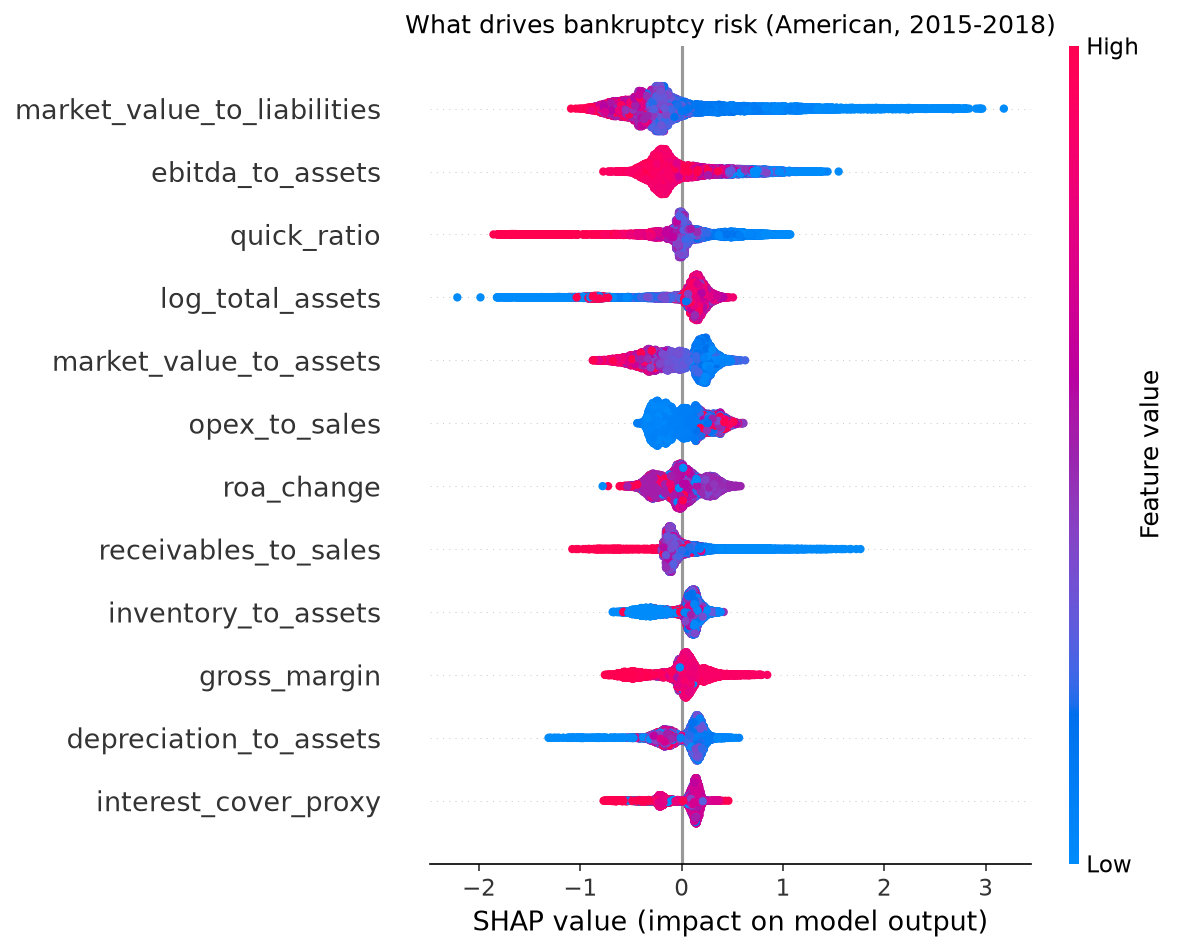

In [15]:
print(pd.read_csv(RES/"american/shap_importance.csv", index_col=0).head(10).round(3))
display(Image(str(RES/"american/figures/shap_summary.png"), width=620))

Market value relative to debt dominates, followed by EBITDA / assets, the quick ratio, firm size and market value / assets.

## 8. Neural net fix
The plain MLP ignores the rare bankrupt class. Oversampling bankrupt rows inside each training fold fixes the collapse under MinMax / Z-score (AUC 0.57 / 0.63 to about 0.84) but it stays behind the tree models.

In [16]:
pd.read_csv(RES/"american/nn_balanced.csv").drop(columns="best_params").round(3)

,scaling,auc_before,auc_after,recall_before,recall_after,f1_before,f1_after
0,log,0.862,0.844,0.370,0.269,0.137,0.205
1,minmax,0.571,0.848,0.042,0.202,0.029,0.150
2,zscore,0.633,0.830,0.118,0.193,0.056,0.201


## 9. Try it: score a company
The app (`streamlit run app.py`) wraps this function. The two examples are real firm-years from the held-out 2015-2018 period.

In [17]:
import sys
sys.path.insert(0, str(ROOT / "src"))
import warnings; warnings.filterwarnings("ignore")
from predict import predict_company, load
art = load()
for label, ex in art["examples"].items():
    r = predict_company(ex["items"], ex["prior"])
    print(f"{label}: score {r['bankruptcy_score']:.0%} (alert level {r['threshold']:.0%}) ->", "HIGH RISK" if r["high_risk"] else "low risk")
    for d in r["drivers"][:3]:
        print(f"     {d['ratio']:30s} {d['value']:.2f}  {d['effect']}")

Example: a firm that later failed (caught by the model): score 82% (alert level 81%) -> HIGH RISK
     market_value_to_liabilities    0.00  raises risk
     quick_ratio                    0.22  raises risk
     liabilities_to_assets          1.09  raises risk
Example: a healthy firm: score 5% (alert level 81%) -> low risk
     roa_change                     -0.01  lowers risk
     ebitda_to_assets               0.10  lowers risk
     market_value_to_assets         0.75  raises risk


## 10. Limitations (state these plainly)
* **Different data from the paper.** The paper uses non-financial SME features; here only financial ratios are available, so the method is reproduced, not the findings.
* **Low precision at the real base rate.** American failures are about 1% of firm-years: the model ranks risk well (AUC about 0.91) but most alerts are false alarms (bankrupt F1 about 0.23 on the full test years).
* **Few failures in test sets** (119 American, 220 Taiwan, 54 Polish): recall and F1 carry wide uncertainty.
* **Polish data**: no firm IDs or dates, so likely leakage (see section 4); used as a benchmark only. The 64 column definitions were checked against the official UCI list and match. The Polish LLM prompt (the 1,000-firm run, 5-years-ahead file) still says "within the next year", copied from the paper's template, so that run is a prompt/label mismatch; the American LLM runs are not affected.
* **LLM results** come from one prompting run (500 firms) and one fine-tuning run on a free Colab GPU; they were not repeated.
* **Taiwan** has no year column, so it cannot show forecasting over time; the American time split does.